In [1]:
#import libraries
import requests
import pandas as pd
import json
import ast
import yaml
import pprint
import json
import os
import numpy as np
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud
import subprocess
subprocess.run(["pip", "install", "textblob"])


CompletedProcess(args=['pip', 'install', 'textblob'], returncode=0)

### Extract tweets

In [2]:
#Create a function called create_twitter_url
def create_twitter_url():
    handle = "NBA"
    max_results = 100
    mrf = "max_results={}".format(max_results)
    q = "query=from:{}".format(handle)
    url = "https://api.twitter.com/2/tweets/search/recent?{}&{}".format(mrf, q)
    return url

# Defining a function called process_yaml which will read in the YAML file and save the contents
def process_yaml():
    with open("config.yaml") as file:
        return yaml.safe_load(file)

# Created a function to access the bearer token from your config.yaml file    
def create_bearer_token(data):
    return data["search_tweets_api"]["bearer_token"]

# Define function called twitter_auth_and_connect to connect to the Twitter API, 
# where you’ll format the headers to pass in your bearer_token and url
def twitter_auth_and_connect(bearer_token, url):
    headers = {"Authorization": "Bearer {}".format(bearer_token)}
    response = requests.request("GET", url, headers=headers)
    return response.json()

# The main function
def main():
#     url = create_twitter_url()
#     print("\nCreating Twitter URL: ")
#     print(url)
#     data = process_yaml()
#     print("\nprocessing YAML file: ")
#     print(data)
#     bearer_token = create_bearer_token(data)
#     print("\nBearer Token: ")
#     print(bearer_token)
#     res_json = twitter_auth_and_connect(bearer_token, url)
#     print("\nResponse Json: ")
#     pprint.pprint(res_json)
    
#     with open("twitter_response.json", "w") as outfile:
#         json.dump(res_json, outfile, indent=4)
#     with open("twitter_response.json", "r") as infile:
#         res_json = json.load(infile)
#     pprint.pprint(res_json)


if __name__ == "__main__":
    main()


Creating Twitter URL: 
https://api.twitter.com/2/tweets/search/recent?max_results=100&query=from:NBA

processing YAML file: 
{'search_tweets_api': {'bearer_token': 'AAAAAAAAAAAAAAAAAAAAADpUlgEAAAAAqtXKKe4bUhUjLU%2Bo6myz5eVY8jA%3Dox4pyfzCJteQperSpiLfPNnwijydxJO6Ai4YFOkZwKvJNQLkn5'}}

Bearer Token: 
AAAAAAAAAAAAAAAAAAAAADpUlgEAAAAAqtXKKe4bUhUjLU%2Bo6myz5eVY8jA%3Dox4pyfzCJteQperSpiLfPNnwijydxJO6Ai4YFOkZwKvJNQLkn5

Response Json: 
{'data': [{'edit_history_tweet_ids': ['1620951332210479104'],
           'id': '1620951332210479104',
           'text': 'WHAT A START IN BOSTON.\n'
                   '\n'
                   '☘️ Tatum: 18 PTS, 5 REB, 4/4 3PM\n'
                   '☘️ Brown: 12 PTS, 3 3PM\n'
                   '☘️ Celtics: 70% FG, 8/9 3PM\n'
                   '\n'
                   'Celtics lead 41-13 on ESPN. https://t.co/VxufBZexfv'},
          {'edit_history_tweet_ids': ['1620950254605434881'],
           'id': '1620950254605434881',
           'text': "THE CELTICS CAN'T MI

### Sentimental Analysis

In [3]:
# Load the JSON file
with open("twitter_response.json", "r") as json_file:
    data = json.load(json_file)

In [14]:
# Access the data within the "data" tag
details = data["data"]

records = []
for i in details:
    text_id = i["id"] # extract the "id" value from the dictionary
    text = i["text"] # extract the "text" value from the dictionary
    sentiment = TextBlob(text).sentiment.polarity
    records.append({"id": text_id, "text": text, "sentiment": sentiment})

In [15]:
# Convert the results to a pandas DataFrame
df = pd.DataFrame(records)

# Save the DataFrame to a CSV file
df.to_csv("tweets_sentiment.csv", index=False)

### Sentiment Average

In [16]:
# To compute the sentiment average 
sentiment_values = [i["sentiment"] for i in records]
avg_sentiment = np.mean(sentiment_values)

print("Average Sentiment:", avg_sentiment)


Average Sentiment: 0.11545919011544013


### Visualization

Text(0.5, 1.0, 'Sentiment Distribution')

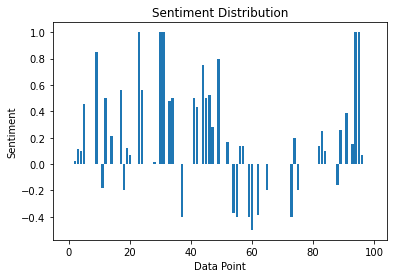

In [7]:
# plot bar chart
plt.bar(range(len(sentiment_values)), sentiment_values)
plt.xlabel("Data Point")
plt.ylabel("Sentiment")
plt.title("Sentiment Distribution")

Based on the data depicted in the graph, it appears that the majority of tweets regarding our client NBA exhibit a positive sentiment, with fewer tweets exhibiting a negative sentiment.

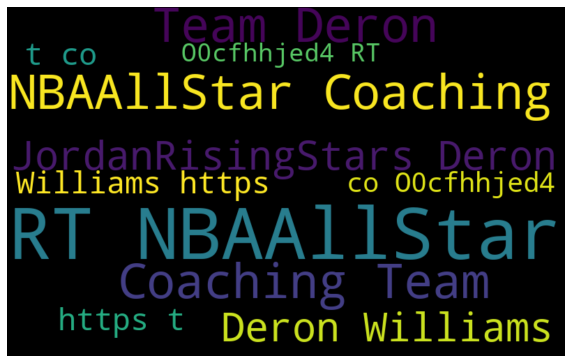

In [17]:
# plot word cloud
all_words = ' '.join([text for item in details])
wordcloud = WordCloud(width=800, height=500, random_state=21, max_font_size=110).generate(all_words)
plt.figure(figsize=(10, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

From the analysis of the word cloud, we can deduce that the prominence of the terms "NBA AllStar" and "Deron" reflects the high level of interest and anticipation surrounding the forthcoming Allstar weekend.The frequency of mentions of coach Deron and coaching team also indicates focus on his role in the Allstar event and the public's perception of him. Overall, the word cloud provides valuable insight into the Twitter community's priorities and priorities surrounding the NBA Allstar weekend.